# 07 — ReMedFiLM model progression and ablation

Component progression and the full 13-arm ablation, with the negative A8-vs-A7 contrast preserved.

**Evidence base**

- `full_doc_report/tables/REMEDFILM_PROGRESSION_RESULTS.csv`
- `full_doc_report/tables/REMEDFILM_ABLATION_RESULTS.csv`
- `reports/tables/phase28_table_08_bootstrap_statistics.csv`

> Execution is `ANALYSIS_ONLY`. Training, new inference and protected TEST access
> are blocked by an installed audit hook (verified below).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, r"D:\Softfors\jup\full_doc_report\Scripts")
import remedfilm_guard as GUARD
GUARD.install()

REPO = Path(r"D:\Softfors\jup")
REPORT = REPO / "full_doc_report"
TABLES = REPORT / "tables"
FIG = REPORT / "figures"

import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

def fig(subdir, name, width=760):
    """Display a generated figure, failing loudly if it is missing."""
    p = FIG / subdir / f"{name}.png"
    if not p.exists():
        raise FileNotFoundError(f"missing figure: {p}")
    display(Image(filename=str(p), width=width))

def table(path, **kw):
    return pd.read_csv(path, **kw)

GUARD.require()

True

In [2]:
# Negative control — enforcement must be real, not a flag.
for name, verdict in GUARD.self_test():
    print(f"  {name:28s}: {verdict}")
assert all(v.startswith("blocked") for _, v in GUARD.self_test()), "GUARD FAILED"
print("analysis-only guard verified")

  optimiser construction      : blocked
  AdamW construction          : blocked
  TEST manifest read          : blocked
  write outside report dir    : blocked
analysis-only guard verified


## 7.1 Component progression

In [3]:
prog = pd.read_csv(TABLES / "REMEDFILM_PROGRESSION_RESULTS.csv")
prog[["stage", "stage_name", "population", "n", "mean_dice", "net_delta_pp",
      "harm_rate", "gmacs_lower_bound", "evidence_class"]].to_string(index=False)

'     stage                        stage_name              population    n  mean_dice  net_delta_pp  harm_rate  gmacs_lower_bound                     evidence_class\n   Stage 0        GlobalMedFiLM backbone (G)                  VAL808  808    0.83508      0.000000   0.000000          31.551741          FROZEN_BACKBONE_REFERENCE\n   Stage 1 Unrouted regional refinement (A1) ROUTER_DEVELOPMENT_4957 4957        NaN      0.165808   0.426669          34.782441 IN_SAMPLE_ENDPOINT_BY_CONSTRUCTION\n   Stage 2      Learned benefit routing (A7) ROUTER_DEVELOPMENT_4957 4957        NaN      0.724663   0.332526          32.437902               DEVELOPMENT_EVIDENCE\n   Stage 3        Post-safety gate (A8 FULL) ROUTER_DEVELOPMENT_4957 4957        NaN      0.751575   0.323651          32.437902               DEVELOPMENT_EVIDENCE\n   Stage 4  FULL assembly on held-out VAL808                  VAL808  808    0.83729      0.220997   0.120050          32.437902       PAIRED_PRESERVATION_EVIDENCE\nAudit gat

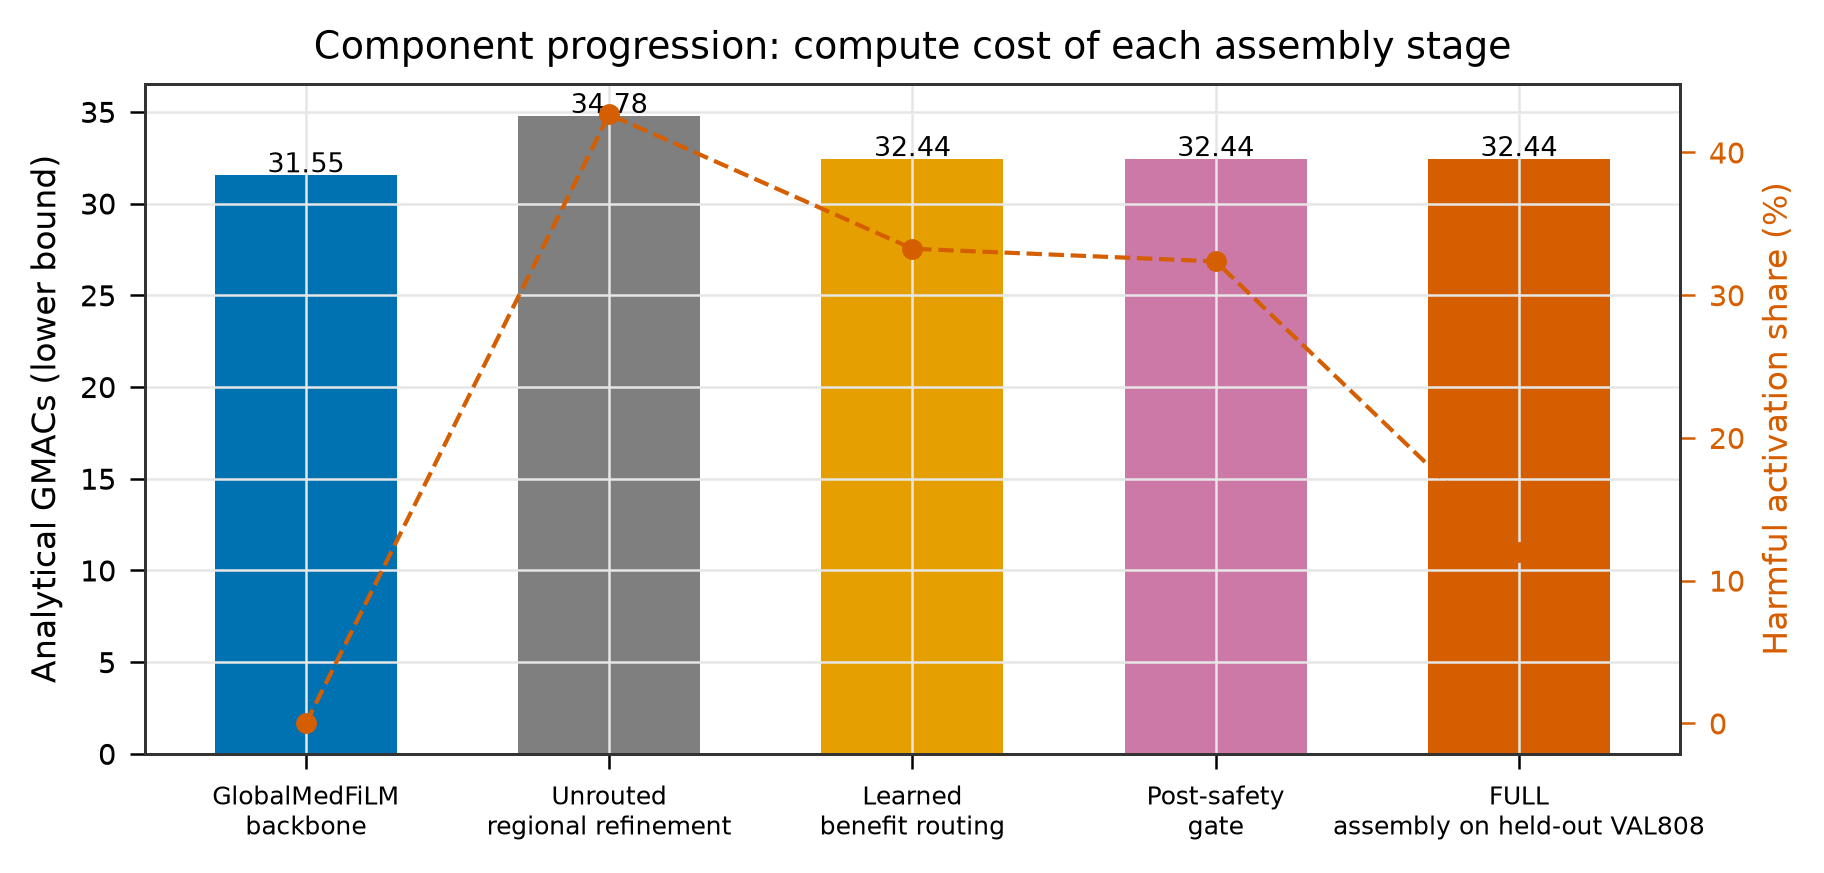

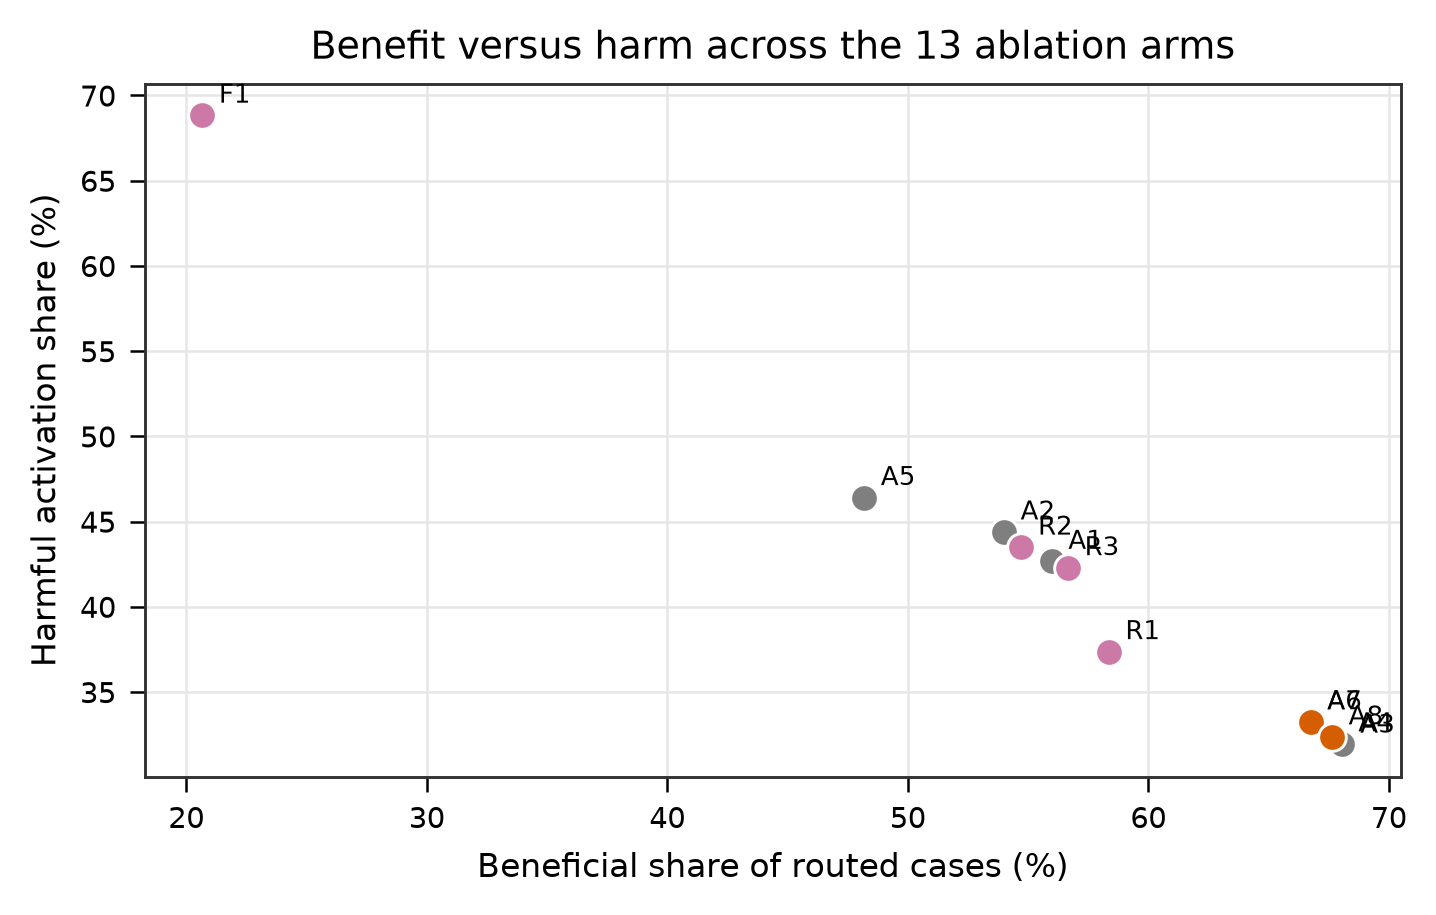

In [4]:
fig("Progression", "PROG01_stage_compute_and_harm", width=740)
fig("Progression", "PROG02_benefit_harm_tradeoff", width=620)

### Population warning

Stage 0 and Stage 4 are measured on **VAL808**. Stages 1–3 are measured on
**ROUTER_DEVELOPMENT (4,957)**. The progression is therefore *not* a single
monotone curve on one population, and the figure says so.

## 7.2 The 13 arms

In [5]:
abl = pd.read_csv(TABLES / "REMEDFILM_ABLATION_RESULTS.csv")
print("arms:", len(abl))
abl[["arm", "n_routed", "budget_fraction", "mean_true_delta_dice_routed",
     "benefit_capture_vs_positive_mass", "harmful_activation_share",
     "evidence_class"]].to_string(index=False)

arms: 13


'arm  n_routed  budget_fraction  mean_true_delta_dice_routed  benefit_capture_vs_positive_mass  harmful_activation_share                   evidence_class\n A0         0         0.000000                     0.000000                          0.000000                  0.000000         ENDPOINT_BY_CONSTRUCTION\n A1      4957         1.000000                     0.001658                          1.000000                  0.426669         ENDPOINT_BY_CONSTRUCTION\n A2      1239         0.249950                     0.001413                          0.245520                  0.443906   PRIOR_CANONICAL_EVIDENCE_EXACT\n A3      1239         0.249950                     0.007185                          0.584331                  0.318805   PRIOR_CANONICAL_EVIDENCE_EXACT\n A4      1239         0.249950                     0.007119                          0.582158                  0.319613   PRIOR_CANONICAL_EVIDENCE_EXACT\n A5      1239         0.249950                    -0.000433                

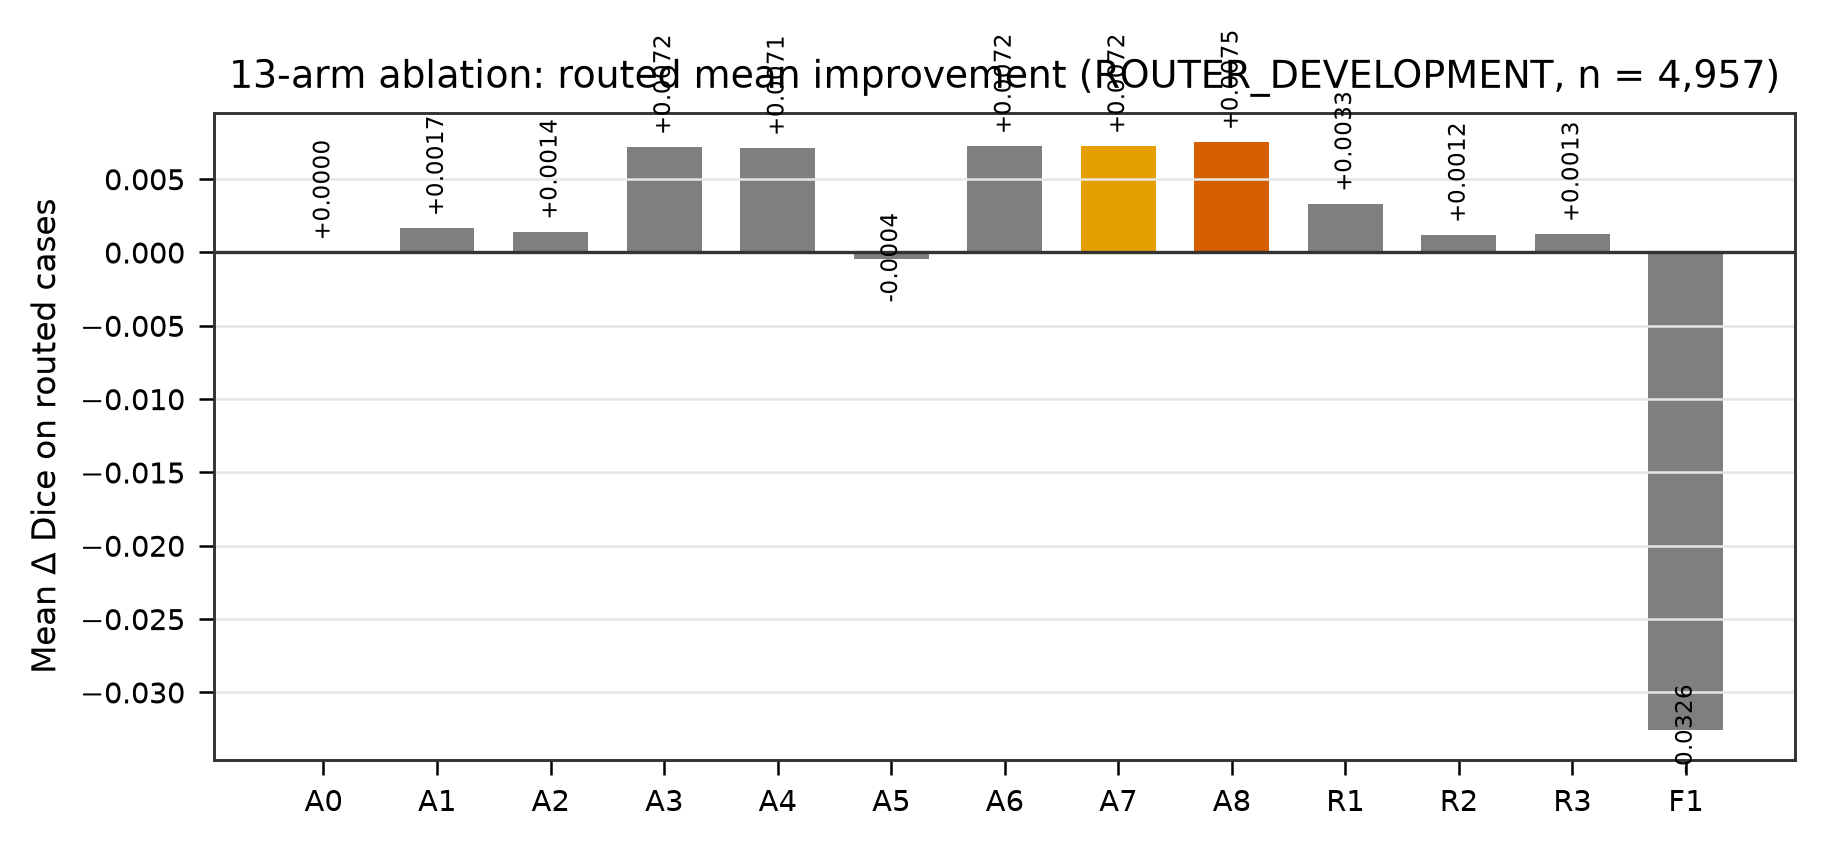

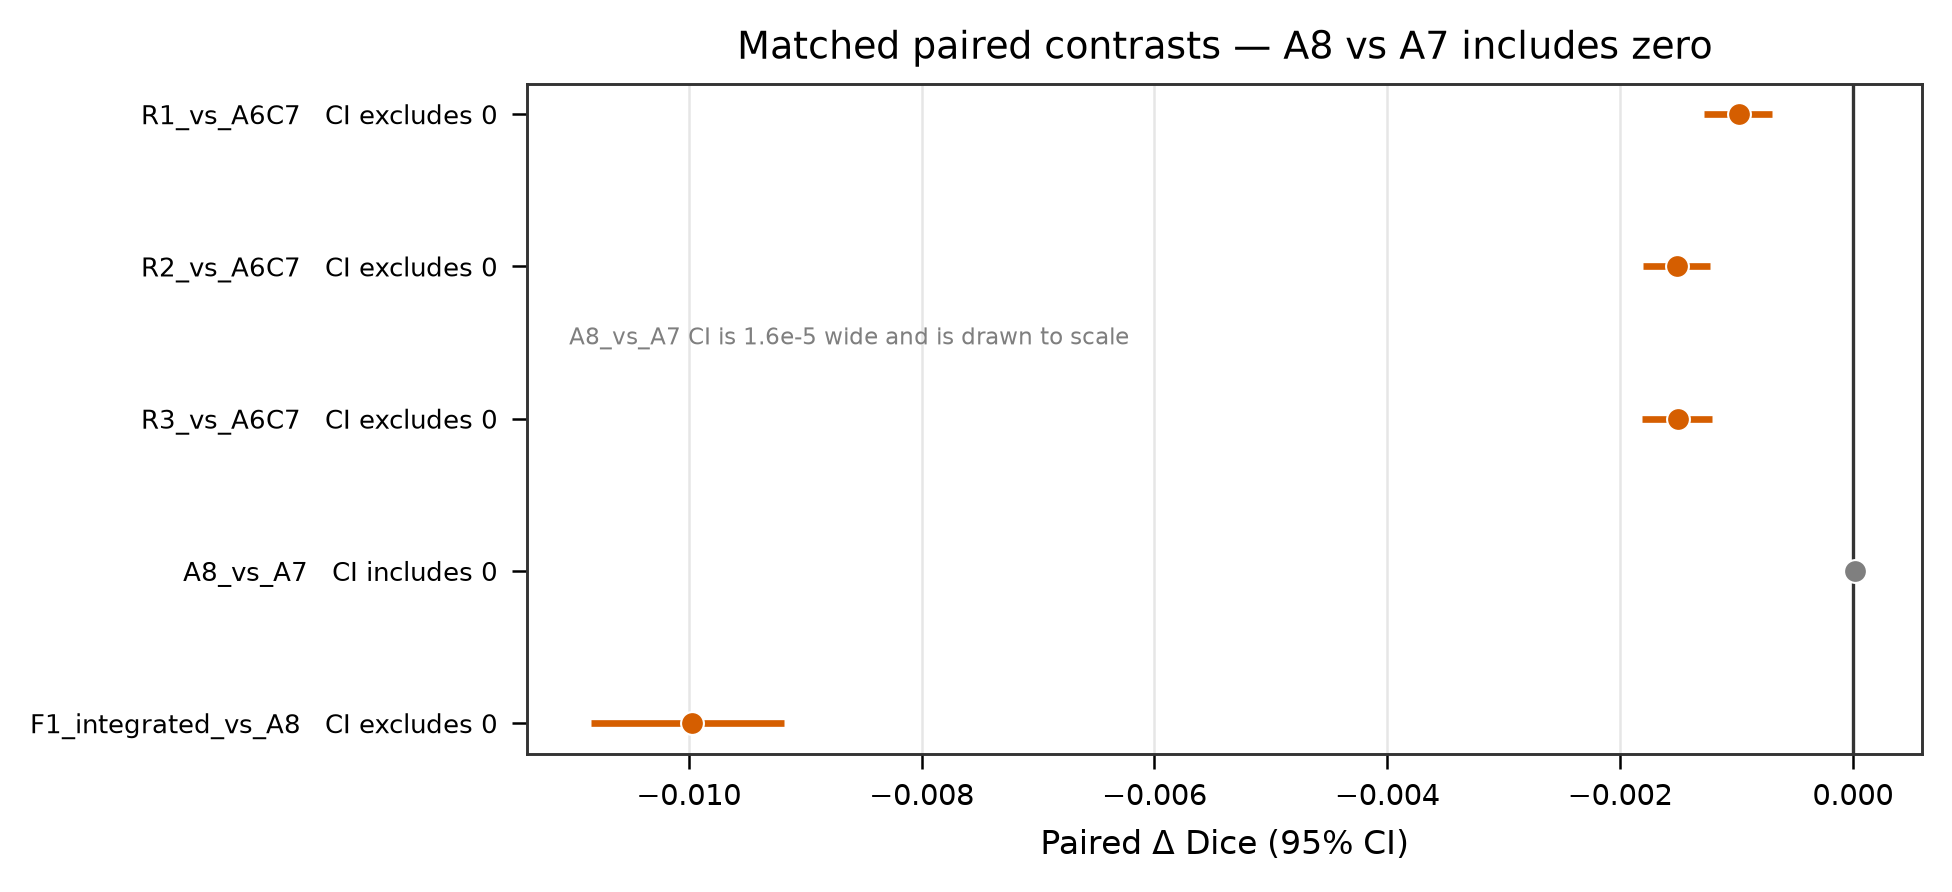

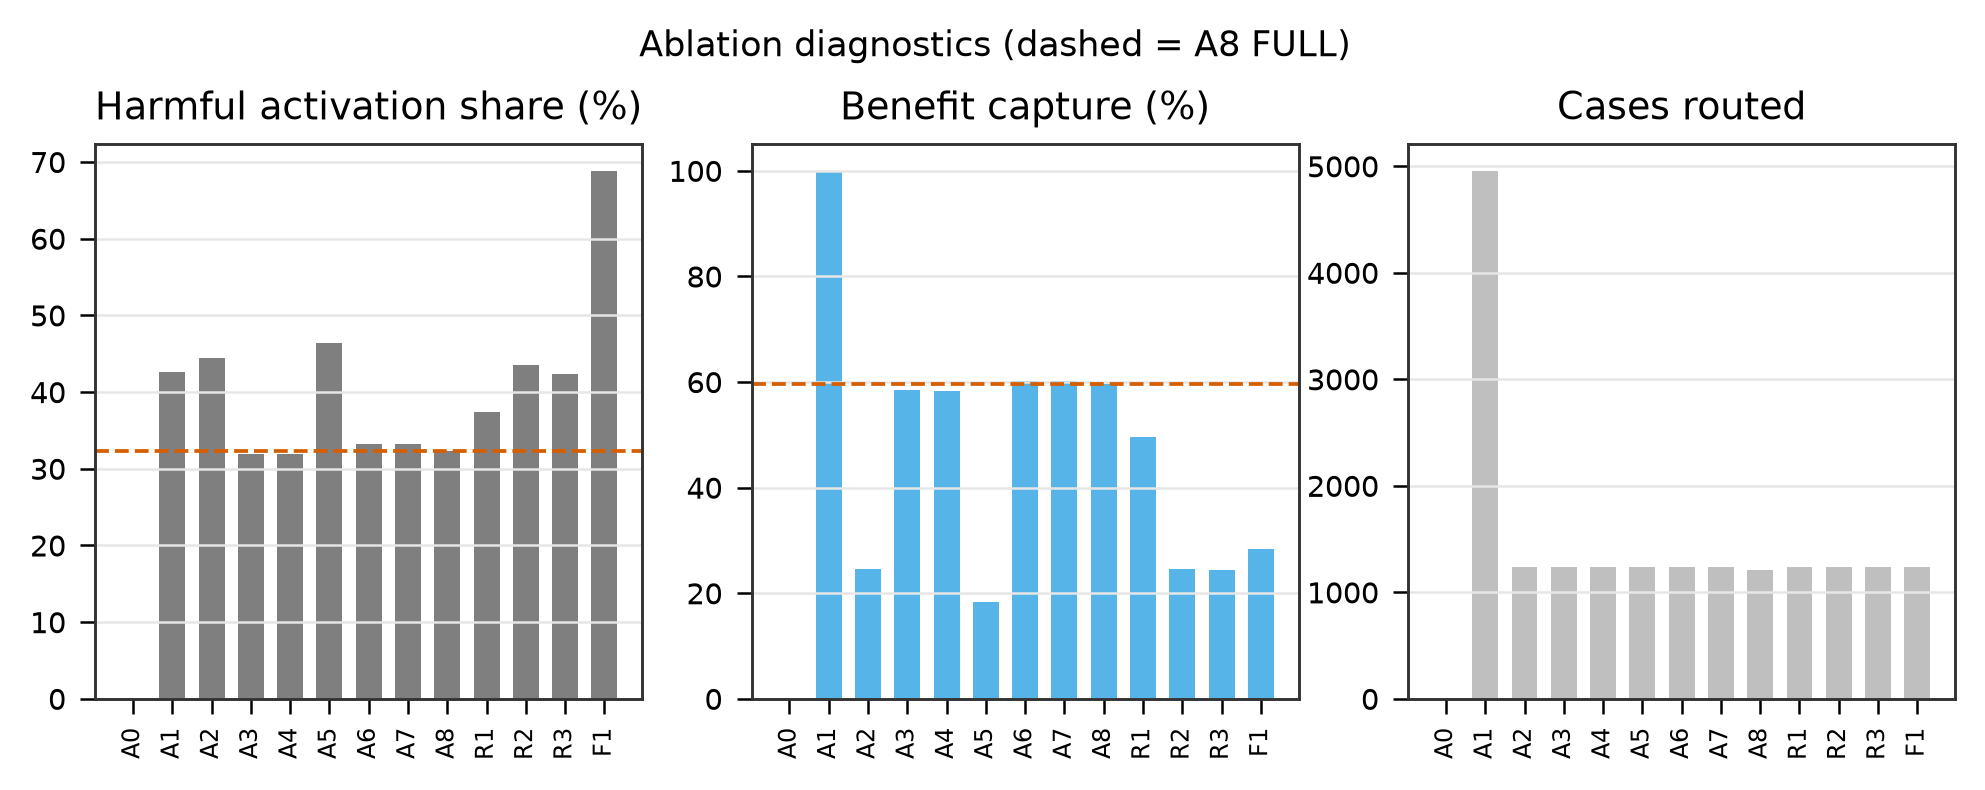

In [6]:
fig("Ablation", "ABL01_arm_mean_delta", width=780)
fig("Ablation", "ABL02_paired_contrasts_forest", width=660)
fig("Ablation", "ABL03_ablation_diagnostics", width=880)

## 7.3 The preserved negative contrast

In [7]:
bs = pd.read_csv(REPO / "reports/tables/phase28_table_08_bootstrap_statistics.csv")
bs["excludes_zero"] = (bs.ci95_low > 0) | (bs.ci95_high < 0)
bs[["contrast", "n", "mean_difference", "ci95_low", "ci95_high", "excludes_zero"]].to_string(index=False)

'           contrast    n  mean_difference  ci95_low  ci95_high  excludes_zero\n         R1_vs_A6C7 4957        -0.000981 -0.001278  -0.000697           True\n         R2_vs_A6C7 4957        -0.001514 -0.001805  -0.001232           True\n         R3_vs_A6C7 4957        -0.001499 -0.001813  -0.001213           True\n           A8_vs_A7 4957         0.000016 -0.000014   0.000051          False\nF1_integrated_vs_A8 4957        -0.009972 -0.010842  -0.009178           True'

In [8]:
a8 = bs[bs.contrast == "A8_vs_A7"].iloc[0]
print("A8 vs A7 :", f"{a8.mean_difference:+.3e}",
      f"[{a8.ci95_low:+.3e}, {a8.ci95_high:+.3e}]")
print("includes zero:", not (a8.ci95_low > 0 or a8.ci95_high < 0))
print()
print("The only PRE-SPECIFIED matched contrast is inconclusive. The safety gate's")
print("marginal contribution is therefore not statistically established, even")
print("though the point estimate is positive.")

A8 vs A7 : +1.572e-05 [-1.431e-05, +5.101e-05]
includes zero: True

The only PRE-SPECIFIED matched contrast is inconclusive. The safety gate's
marginal contribution is therefore not statistically established, even
though the point estimate is positive.


In [9]:
print("Evidence classes in the ablation")
print("--------------------------------")
print(abl.evidence_class.value_counts().to_string())
print()
print("ENDPOINT_BY_CONSTRUCTION arms (A0, A1) are structural, not measured gains.")
print("PRIOR_CANONICAL_EVIDENCE_EXACT arms reuse frozen Phase 25/26 results.")
print("PHASE28_TRAINED_ABLATION_VARIANT arms (R1-R3, F1) were genuinely re-trained.")

Evidence classes in the ablation
--------------------------------
evidence_class
PRIOR_CANONICAL_EVIDENCE_EXACT      7
PHASE28_TRAINED_ABLATION_VARIANT    4
ENDPOINT_BY_CONSTRUCTION            2

ENDPOINT_BY_CONSTRUCTION arms (A0, A1) are structural, not measured gains.
PRIOR_CANONICAL_EVIDENCE_EXACT arms reuse frozen Phase 25/26 results.
PHASE28_TRAINED_ABLATION_VARIANT arms (R1-R3, F1) were genuinely re-trained.


In [10]:
# Negative control — enforcement must be real, not a flag.
for name, verdict in GUARD.self_test():
    print(f"  {name:28s}: {verdict}")
assert all(v.startswith("blocked") for _, v in GUARD.self_test()), "GUARD FAILED"
print("analysis-only guard verified")

  optimiser construction      : blocked
  AdamW construction          : blocked
  TEST manifest read          : blocked
  write outside report dir    : blocked
analysis-only guard verified
